# 03 · CWRU bearing vibration — exploratory analysis (T07)

**Dataset**: Case Western Reserve University Bearing Data Center. Drive-end accelerometer, 12 kHz, motor
load 0 HP. 4 classes used: normal, inner race, ball, outer race (0.007" defects).

**Why we use it**: real vibration signals to validate the **autoencoder** (T16) and the vibration side of
our `BEARING_WEAR` fault, before trusting results on simulated data.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)

In [2]:
from roottwin.datasets import cwru
sig = {k: cwru.load_signal(k) for k in cwru.FILES}
pd.DataFrame({k: {"samples": len(v), "seconds": len(v) / cwru.FS, "rms": np.sqrt((v**2).mean())} for k, v in sig.items()}).T

,samples,seconds,rms
normal,243938.0,20.328,0.074
inner_race,121265.0,10.105,0.292
ball,122571.0,10.214,0.139
outer_race,121991.0,10.166,0.670


## 1. Raw signals (first 0.1 s)

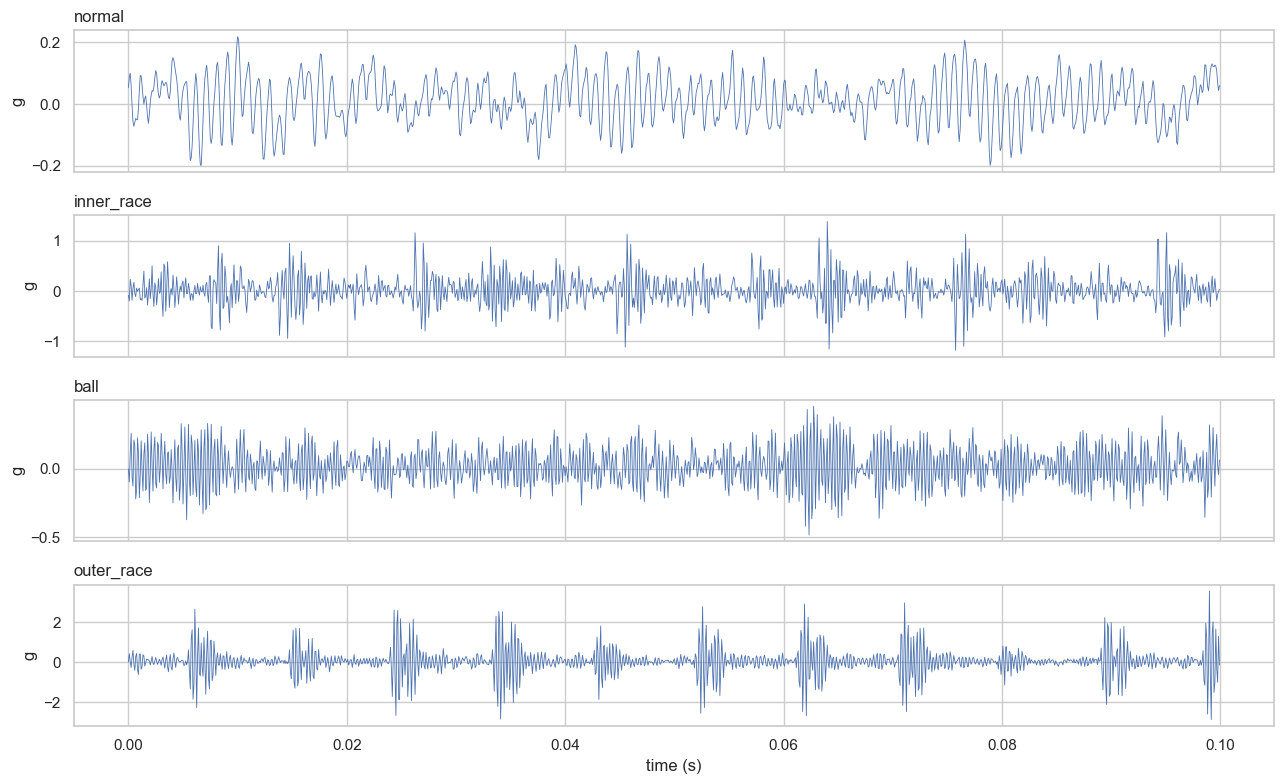

In [3]:
n = int(0.1 * cwru.FS); t = np.arange(n) / cwru.FS
fig, axes = plt.subplots(4, 1, figsize=(13, 8), sharex=True)
for ax, (k, v) in zip(axes, sig.items()):
    ax.plot(t, v[:n], lw=0.6); ax.set_ylabel("g"); ax.set_title(k, loc="left")
axes[-1].set_xlabel("time (s)"); plt.tight_layout()

Faults create **periodic impacts** (each time a ball hits the defect): visible spikes, higher peak and kurtosis.

## 2. Frequency content

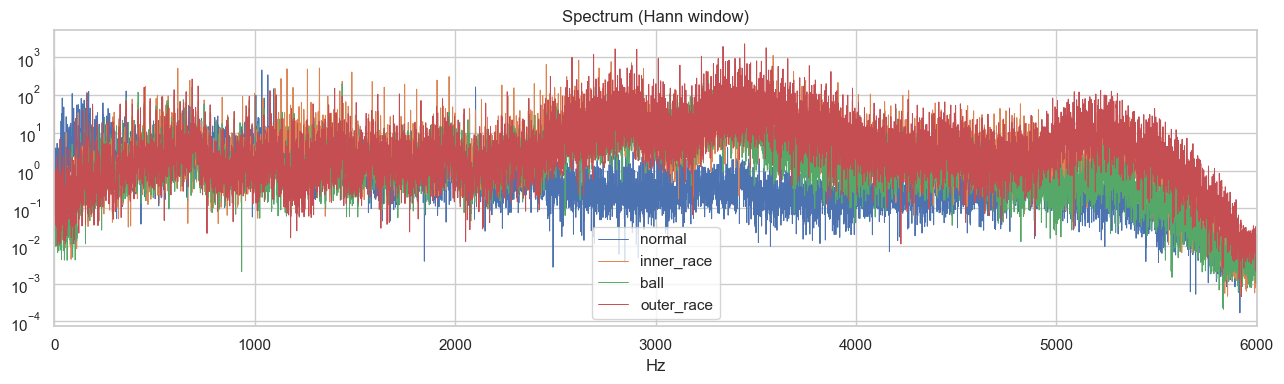

In [4]:
fig, ax = plt.subplots(figsize=(13, 4))
for k, v in sig.items():
    w = v[: 2**15]
    f = np.fft.rfftfreq(len(w), 1 / cwru.FS); a = np.abs(np.fft.rfft(w * np.hanning(len(w))))
    ax.semilogy(f, a, lw=0.7, label=k)
ax.set_xlim(0, 6000); ax.set_xlabel("Hz"); ax.legend(); ax.set_title("Spectrum (Hann window)"); plt.tight_layout()

## 3. Condition indicators per window (2048 samples ≈ 0.17 s)

In [5]:
feats = cwru.load_features()
print(feats.label.value_counts().to_dict())
feats.groupby("label", observed=True)[["rms", "peak", "crest_factor", "kurtosis"]].mean()

{'normal': 119, 'ball': 59, 'inner_race': 59, 'outer_race': 59}


,rms,peak,crest_factor,kurtosis
label,,,,
ball,0.139,0.495,3.558,2.958
inner_race,0.291,1.492,5.119,5.395
normal,0.074,0.235,3.183,2.756
outer_race,0.669,3.278,4.904,7.630


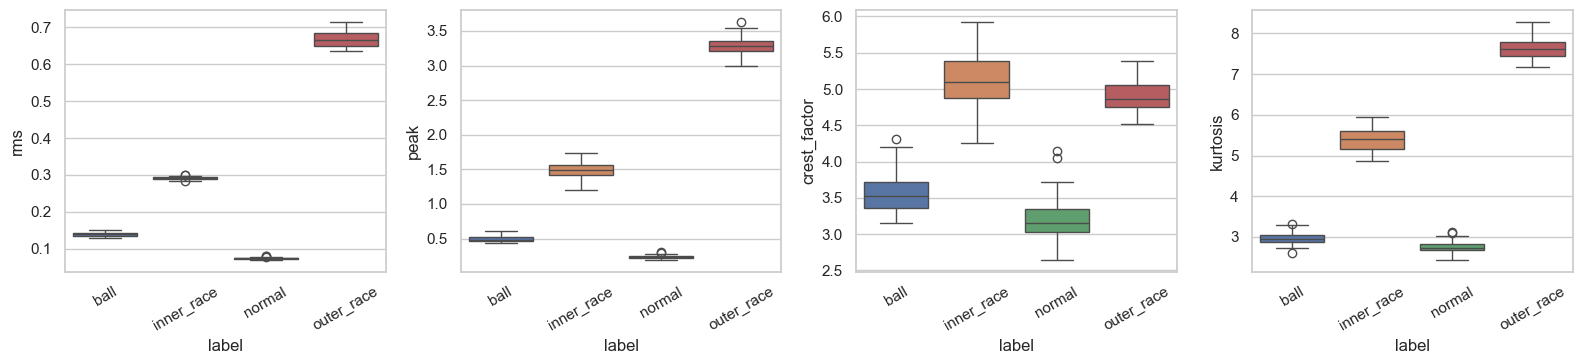

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, c in zip(axes, ["rms", "peak", "crest_factor", "kurtosis"]):
    sns.boxplot(data=feats, x="label", y=c, ax=ax, hue="label", legend=False); ax.tick_params(axis="x", rotation=30)
plt.tight_layout()

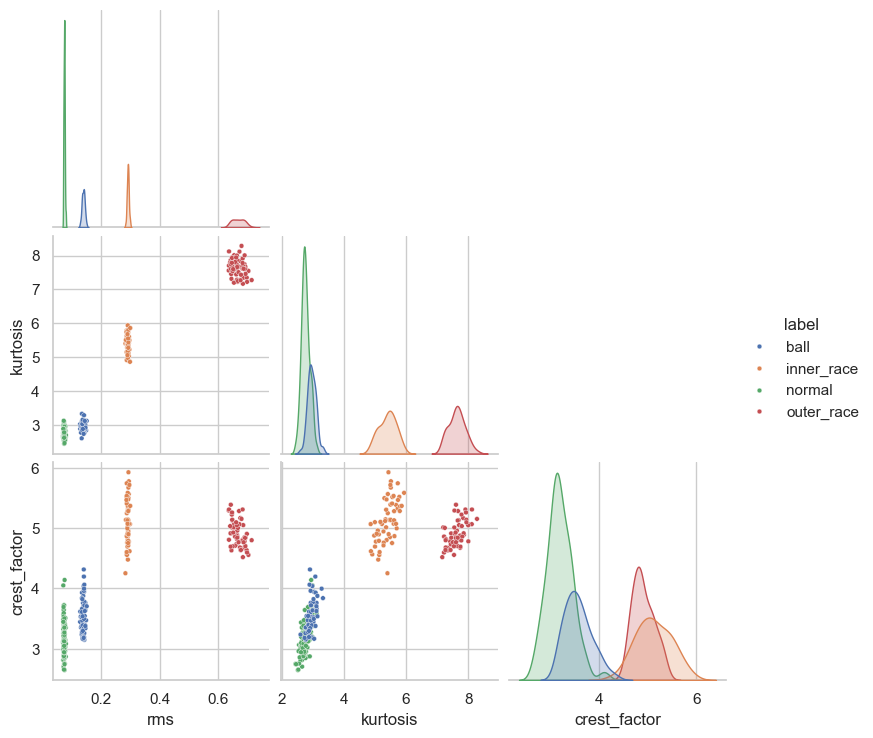

In [7]:
sns.pairplot(feats[["rms", "kurtosis", "crest_factor", "label"]], hue="label", corner=True, plot_kws={"s": 12});

## Takeaways

- Normal vs faulty is separable with 2 features (RMS, kurtosis) → the autoencoder (T16) should reach near-perfect
  detection here; the real test is the simulation and the C-MAPSS-like gradual cases.
- Classes are imbalanced in windows (normal recording is 2x longer) → balance or weight when training classifiers.
- For deep models use the raw windows in `data/processed/cwru_windows.npz` (75 % overlap, `X` shape `(n, 2048)`).
- Our simulator only publishes a vibration **RMS** (mm/s): the CWRU features show what a richer vibration sensor
  would add (kurtosis is the early bearing-fault indicator).